# Employee Attrition Analysis

This notebook demonstrates the **release-safe** cleaning checks and exploratory analysis. It uses only `data/employee_attrition_deidentified.csv`; names, employee numbers, exact ages, exact compensation, and the original raw workbook are intentionally not included.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path('../data/employee_attrition_deidentified.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('data/employee_attrition_deidentified.csv')
df = pd.read_csv(DATA_PATH)
df.head()

,Attrition,Attrition_Flag,BusinessTravel,Department,EducationField,EnvironmentSatisfaction,JobInvolvement,JobLevel,JobRole,JobSatisfaction,OverTime,PerformanceRating,RelationshipSatisfaction,WorkLifeBalance,Age_Band,Salary_Band,Experience_Band,Tenure_Band
0,Yes,1,Travel_Rarely,Sales,Life Sciences,2,3,2,Sales Executive,4,Yes,3,1,1,35 to 44,"5,000 to 7,999",6 to 10 yrs,5 to 9 yrs
1,No,0,Travel_Frequently,Research & Development,Life Sciences,3,2,2,Research Scientist,2,No,4,4,3,45 to 54,"5,000 to 7,999",6 to 10 yrs,10+ yrs
2,Yes,1,Travel_Rarely,Research & Development,Other,4,2,1,Laboratory Technician,3,Yes,3,2,3,35 to 44,"Under 3,000",6 to 10 yrs,0 to 1 yrs
3,No,0,Travel_Frequently,Research & Development,Life Sciences,4,3,1,Research Scientist,3,Yes,3,3,3,25 to 34,"Under 3,000",6 to 10 yrs,5 to 9 yrs
4,No,0,Travel_Rarely,Research & Development,Medical,1,3,1,Laboratory Technician,2,No,3,4,3,25 to 34,"3,000 to 4,999",6 to 10 yrs,2 to 4 yrs


## 1. Initial inspection and release-safety checks

The private preprocessing removed direct identifiers and converted sensitive numerical attributes to broad bands. The checks below are performed on the public release.

In [2]:
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
print('Missing values:', int(df.isna().sum().sum()))
print('Exact duplicate rows:', int(df.duplicated().sum()))
forbidden = {'EmployeeNumber','Employee Name','Employee No','Age','MonthlyIncome','DailyRate','HourlyRate','MonthlyRate'}
assert forbidden.isdisjoint(df.columns)
assert df['Attrition'].isin(['Yes','No']).all()
assert df['Attrition_Flag'].eq(df['Attrition'].eq('Yes').astype(int)).all()
print('Publication-safety checks: passed')

Shape: (1470, 18)
Columns: ['Attrition', 'Attrition_Flag', 'BusinessTravel', 'Department', 'EducationField', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'OverTime', 'PerformanceRating', 'RelationshipSatisfaction', 'WorkLifeBalance', 'Age_Band', 'Salary_Band', 'Experience_Band', 'Tenure_Band']
Missing values: 0
Exact duplicate rows: 0
Publication-safety checks: passed


## 2. Cleaning and validation decisions

The upstream private cleaning process resolved duplicate employee IDs against the separate employee reference sheet, standardized department variants, filled 21 missing ages from that reference, and removed constant columns. Those steps cannot be repeated from the public release because identifiers and exact ages are deliberately absent. The public notebook therefore validates the resulting release rather than pretending to clean unavailable private identifiers.

In [3]:
# Release-level formatting checks: trim categorical text and validate categories.
cat_cols = ['Attrition','BusinessTravel','Department','EducationField','JobRole','OverTime',
            'Age_Band','Salary_Band','Experience_Band','Tenure_Band']
for col in cat_cols:
    df[col] = df[col].astype('string').str.strip()
assert all((df[c] != '').all() for c in cat_cols)
assert set(df['Department']) == {'Sales','Research & Development','Human Resources'}
print('Release-level validation: passed')

Release-level validation: passed


## 3. Overall attrition

In [4]:
overall = df['Attrition_Flag'].mean()
summary = pd.DataFrame({'Metric':['Employees','Employees who left','Overall attrition rate'],
                       'Value':[len(df), int(df['Attrition_Flag'].sum()), f'{overall:.1%}']})
summary

,Metric,Value
0,Employees,1470
1,Employees who left,237
2,Overall attrition rate,16.1%


## 4. Grouped attrition analysis

In [5]:
def attrition_rate(data, column):
    return (data.groupby(column, observed=True)['Attrition_Flag']
            .agg(employees='size', leavers='sum', attrition_rate='mean')
            .sort_values('attrition_rate', ascending=False)
            .assign(attrition_rate=lambda x: x['attrition_rate'].map(lambda v: f'{v:.1%}')))

for column in ['Department','JobRole','OverTime','Age_Band','Salary_Band','Experience_Band','Tenure_Band']:
    print('\n', column)
    display(attrition_rate(df, column))


 Department


,employees,leavers,attrition_rate
Department,,,
Sales,446,92,20.6%
Human Resources,63,12,19.0%
Research & Development,961,133,13.8%



 JobRole


,employees,leavers,attrition_rate
JobRole,,,
Sales Representative,83,33,39.8%
Laboratory Technician,259,62,23.9%
Human Resources,52,12,23.1%
Sales Executive,326,57,17.5%
Research Scientist,292,47,16.1%
Manufacturing Director,145,10,6.9%
Healthcare Representative,131,9,6.9%
Manager,102,5,4.9%
Research Director,80,2,2.5%



 OverTime


...

,employees,leavers,attrition_rate
Salary_Band,,,
"Under 3,000",395,113,28.6%
"8,000 to 11,999",186,29,15.6%
"3,000 to 4,999",354,50,14.1%
"5,000 to 7,999",340,34,10.0%
"12,000 and over",195,11,5.6%



 Experience_Band


,employees,leavers,attrition_rate
Experience_Band,,,
0 to 2 yrs,123,54,43.9%
3 to 5 yrs,193,37,19.2%
6 to 10 yrs,607,91,15.0%
11 to 20 yrs,340,39,11.5%
21+ yrs,207,16,7.7%



 Tenure_Band


,employees,leavers,attrition_rate
Tenure_Band,,,
0 to 1 yrs,215,75,34.9%
2 to 4 yrs,365,66,18.1%
5 to 9 yrs,524,58,11.1%
10+ yrs,366,38,10.4%


## 5. Visualizations

The repository includes four charts generated from the same de-identified extract.

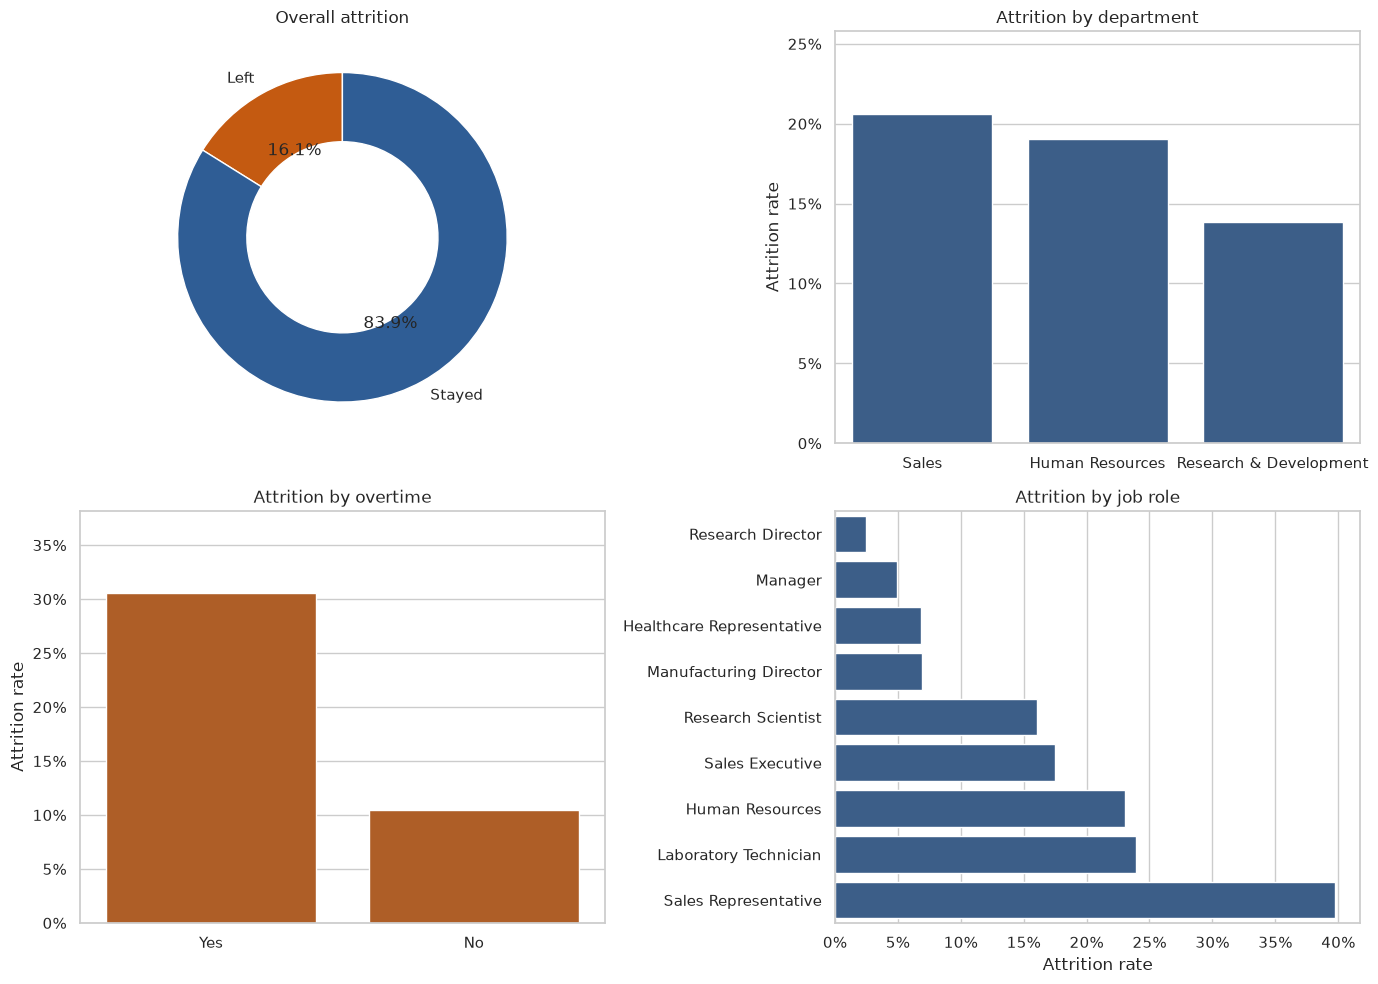

In [6]:
sns.set_theme(style='whitegrid', context='notebook')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Overview
axes[0,0].pie([df['Attrition_Flag'].sum(), len(df)-df['Attrition_Flag'].sum()], labels=['Left','Stayed'], colors=['#c45a11','#2f5d95'], startangle=90, wedgeprops={'width':0.42}, autopct='%1.1f%%')
axes[0,0].set_title('Overall attrition')

for ax, col, title, color in [(axes[0,1],'Department','Attrition by department','#2f5d95'), (axes[1,0],'OverTime','Attrition by overtime','#c45a11')]:
    tmp = df.groupby(col, observed=True)['Attrition_Flag'].mean().sort_values(ascending=False)
    sns.barplot(x=tmp.index, y=tmp.values, color=color, ax=ax)
    ax.set_title(title); ax.set_ylabel('Attrition rate'); ax.set_xlabel('')
    ax.set_ylim(0, max(tmp.values)*1.25)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x:.0%}'))

role = df.groupby('JobRole', observed=True)['Attrition_Flag'].mean().sort_values()
sns.barplot(x=role.values, y=role.index, color='#2f5d95', ax=axes[1,1])
axes[1,1].set_title('Attrition by job role'); axes[1,1].set_xlabel('Attrition rate'); axes[1,1].set_ylabel('')
axes[1,1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x:.0%}'))
plt.tight_layout()
plt.show()

## 6. Findings and conclusion

The strongest observed patterns are higher attrition among overtime employees, employees with 0–2 years of total experience, and selected roles such as Sales Representatives. These findings support workload review, early-career onboarding and role-specific retention analysis. They are associations only; follow-up analysis and carefully governed interventions are required before drawing causal or individual-level conclusions.